# Đáp án đơn giản – Gapminder (Biểu diễn trực quan hóa dữ liệu)
Đặt `gap-every-five-years.xlsx` cùng thư mục. Cần: pandas, matplotlib, seaborn, scipy, plotly, wordcloud, squarify, networkx, matplotlib-venn.

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

folder = 'C:/Users/DELL/Documents/Storage/UEH/Biểu diễn trực quan dữ liệu/SPROJECT6_UEH_DATA-VISUALISATION/Data'
df = pd.read_csv(folder + '/gap-every-five-years.csv', encoding = 'utf-8')
print(df)
sea = ["Vietnam","Thailand","Cambodia","Indonesia","Malaysia","Myanmar","Philippines","Singapore"]
five = ["Vietnam","China","India","Japan","Brazil"]
cs = ["Vietnam","Thailand","Japan","United States"]

          country  year  lifeExp         pop   gdpPercap
0     Afghanistan  1952   28.801   8425333.0  779.445314
1     Afghanistan  1957   30.332   9240934.0  820.853030
2     Afghanistan  1962   31.997  10267083.0  853.100710
3     Afghanistan  1967   34.020  11537966.0  836.197138
4     Afghanistan  1972   36.088  13079460.0  739.981106
...           ...   ...      ...         ...         ...
1699     Zimbabwe  1987   62.351   9216418.0  706.157306
1700     Zimbabwe  1992   60.377  10704340.0  693.420786
1701     Zimbabwe  1997   46.809  11404948.0  792.449960
1702     Zimbabwe  2002   39.989  11926563.0  672.038623
1703     Zimbabwe  2007   43.487  12311143.0  469.709298

[1704 rows x 5 columns]


## Câu 1. Đọc và khám phá dữ liệu

### 1a) Đọc dữ liệu

In [3]:
print(df.shape)
print(df.dtypes)
df.head()

(1704, 5)
country          str
year           int64
lifeExp      float64
pop          float64
gdpPercap    float64
dtype: object


,country,year,lifeExp,pop,gdpPercap
0,Afghanistan,1952,28.801,8425333.0,779.445314
1,Afghanistan,1957,30.332,9240934.0,820.853030
2,Afghanistan,1962,31.997,10267083.0,853.100710
3,Afghanistan,1967,34.020,11537966.0,836.197138
4,Afghanistan,1972,36.088,13079460.0,739.981106


### 1b) Kiểm tra dữ liệu

In [4]:
print(df.isna().sum())
print("Dòng trùng:", df.duplicated().sum())
print("Số quốc gia:", df["country"].nunique())
print("Các năm:", sorted(df["year"].unique()))
df.describe()

country      0
year         0
lifeExp      0
pop          0
gdpPercap    0
dtype: int64
Dòng trùng: 0
Số quốc gia: 142
Các năm: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]


,year,lifeExp,pop,gdpPercap
count,1704.00000,1704.000000,1.704000e+03,1704.000000
mean,1979.50000,59.474439,2.960121e+07,7215.327081
std,17.26533,12.917107,1.061579e+08,9857.454543
min,1952.00000,23.599000,6.001100e+04,241.165876
25%,1965.75000,48.198000,2.793664e+06,1202.060309
50%,1979.50000,60.712500,7.023596e+06,3531.846988
75%,1993.25000,70.845500,1.958522e+07,9325.462346
max,2007.00000,82.603000,1.318683e+09,113523.132900


### 1c) Biến dẫn xuất, lọc, xuất CSV

In [5]:
df["gdp"] = df["gdpPercap"] * df["pop"]      # dùng df["pop"], không dùng df.pop
d07 = df[df["year"] == 2007].copy()
print(d07.nlargest(5, "lifeExp")[["country", "lifeExp"]])
d07.to_csv("gapminder_2007.csv", index=False, encoding="utf-8-sig")

               country  lifeExp
803              Japan   82.603
671   Hong Kong, China   82.208
695            Iceland   81.757
1487       Switzerland   81.701
71           Australia   81.235


### 1d) Biến động theo thời gian

In [6]:
s = df.sort_values(["country", "year"]).copy()
s["dLife"] = s.groupby("country")["lifeExp"].diff()
drops = s[s["dLife"] < 0]
print("Số kỳ giảm:", len(drops), "| số nước từng giảm:", drops["country"].nunique())
print(drops.nsmallest(5, "dLife")[["country", "year", "dLife"]])
print(drops.groupby("year").size())

Số kỳ giảm: 102 | số nước từng giảm: 52
        country  year   dLife
1292     Rwanda  1992 -20.421
1701   Zimbabwe  1997 -13.568
886     Lesotho  2002 -10.965
1462  Swaziland  2002 -10.420
165    Botswana  1997 -10.189
year
1962     1
1972     4
1977     5
1982     8
1987     7
1992    24
1997    23
2002    25
2007     5
dtype: int64


### 1e) Tốc độ tăng trưởng kép (CAGR)

In [7]:
for c in ["Vietnam", "Thailand", "China"]:
    v = df[df["country"] == c].set_index("year")["gdpPercap"]
    cagr = (v[2007] / v[1952]) ** (1 / 55) - 1
    print(c, f"{cagr:.2%}/năm", f"gấp {v[2007]/v[1952]:.1f} lần")

Vietnam 2.57%/năm gấp 4.0 lần
Thailand 4.25%/năm gấp 9.8 lần
China 4.68%/năm gấp 12.4 lần


### 1f) Trung bình có trọng số

In [8]:
tb = df.groupby("year")["lifeExp"].mean()
tw = df.groupby("year").apply(lambda x: np.average(x["lifeExp"], weights=x["pop"]))
res = pd.DataFrame({"không trọng số": tb, "theo dân số": tw})
res["chênh lệch"] = res["theo dân số"] - res["không trọng số"]
res.round(2)

,không trọng số,theo dân số,chênh lệch
year,,,
1952,49.06,48.94,-0.11
1957,51.51,52.12,0.61
1962,53.61,52.32,-1.28
1967,55.68,56.98,1.31
1972,57.65,59.51,1.87
1977,59.57,61.24,1.67
1982,61.53,62.88,1.35
1987,63.21,64.42,1.20
1992,64.16,65.65,1.49


### 1g) Rời rạc hoá biến liên tục

In [9]:
d07["tier"] = pd.cut(d07["gdpPercap"], [0, 2000, 10000, np.inf], labels=["Thấp", "Trung bình", "Cao"])
d07["lifeGrp"] = pd.cut(d07["lifeExp"], [0, 60, 72, 100], labels=["<60", "60–72", ">72"])
pd.crosstab(d07["tier"], d07["lifeGrp"], margins=True)

lifeGrp,<60,60–72,>72,All
tier,,,,
Thấp,30,10,0,40
Trung bình,10,16,22,48
Cao,3,3,48,54
All,43,29,70,142


## Câu 2. Biểu đồ theo trục thời gian

### 2a) Line graph

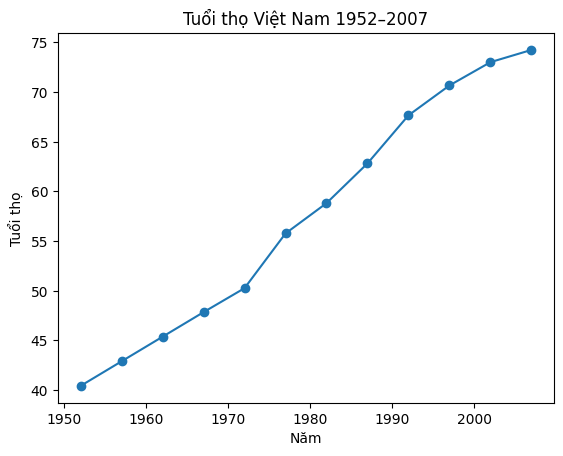

In [10]:
vn = df[df["country"] == "Vietnam"]
plt.plot(vn["year"], vn["lifeExp"], marker="o")
plt.title("Tuổi thọ Việt Nam 1952–2007"); plt.xlabel("Năm"); plt.ylabel("Tuổi thọ")
plt.show()

### 2b) Line graph nhiều nhóm

Vietnam vượt 70 tuổi năm: 1997
Thailand vượt 70 tuổi năm: 2007
Japan vượt 70 tuổi năm: 1967
United States vượt 70 tuổi năm: 1962


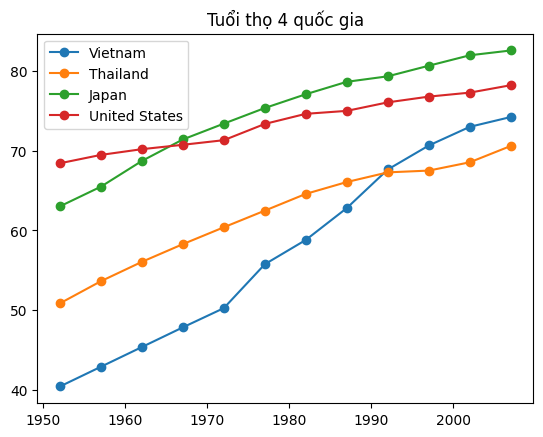

Khoảng cách Nhật–VN: 22.6 -> 8.4


In [11]:
for c in cs:
    d = df[df["country"] == c]
    plt.plot(d["year"], d["lifeExp"], marker="o", label=c)
    print(c, "vượt 70 tuổi năm:", d.loc[d["lifeExp"] >= 70, "year"].min())
plt.legend(); plt.title("Tuổi thọ 4 quốc gia"); plt.show()

jp = df[df.country == "Japan"].set_index("year")["lifeExp"]
vv = df[df.country == "Vietnam"].set_index("year")["lifeExp"]
print("Khoảng cách Nhật–VN:", round(jp[1952]-vv[1952], 1), "->", round(jp[2007]-vv[2007], 1))

### 2c) Dot plot

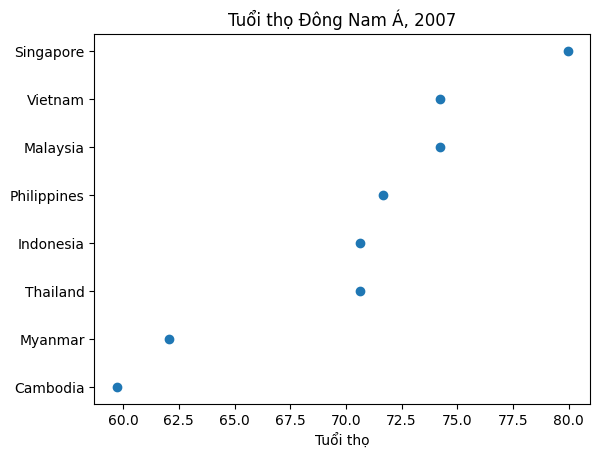

In [12]:
d = d07[d07["country"].isin(sea)].sort_values("lifeExp")
plt.plot(d["lifeExp"], d["country"], "o")
plt.title("Tuổi thọ Đông Nam Á, 2007"); plt.xlabel("Tuổi thọ"); plt.show()

### 2d) Radar chart

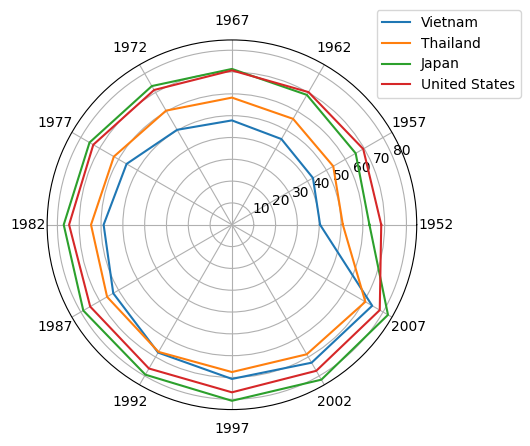

In [13]:
years = sorted(df["year"].unique())
ang = np.linspace(0, 2*np.pi, len(years), endpoint=False)
ax = plt.subplot(polar=True)
for c in cs:
    v = df[df["country"] == c]["lifeExp"].values
    ax.plot(np.append(ang, ang[0]), np.append(v, v[0]), label=c)
ax.set_xticks(ang); ax.set_xticklabels(years)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1)); plt.show()

### 2e) Area và stacked area

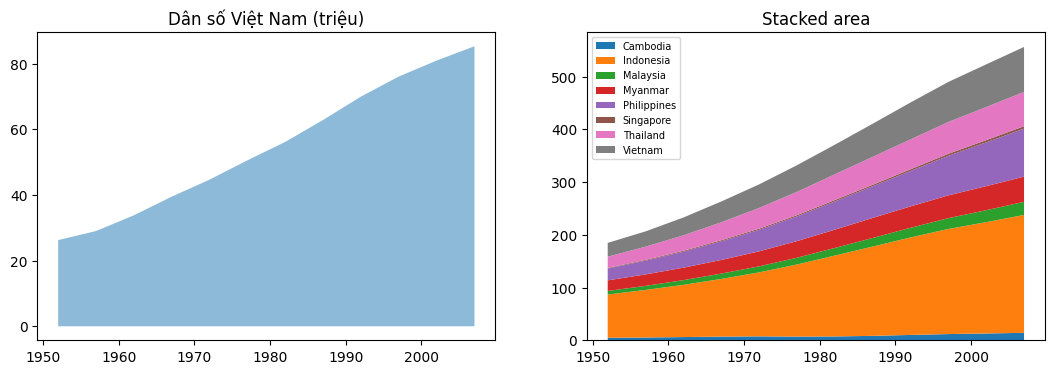

In [14]:
pv = df[df["country"].isin(sea)].pivot(index="year", columns="country", values="pop") / 1e6
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].fill_between(pv.index, pv["Vietnam"], alpha=.5); axs[0].set_title("Dân số Việt Nam (triệu)")
axs[1].stackplot(pv.index, pv.T.values, labels=pv.columns); axs[1].legend(fontsize=7); axs[1].set_title("Stacked area")
plt.show()

### 2f) Stream graph

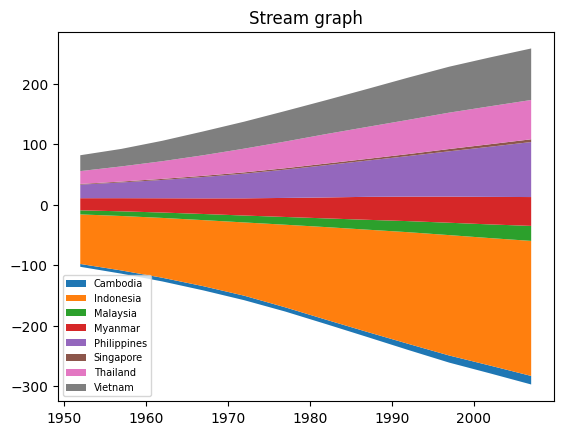

In [15]:
plt.stackplot(pv.index, pv.T.values, baseline="wiggle", labels=pv.columns)
plt.legend(fontsize=7); plt.title("Stream graph"); plt.show()

### 2g) So sánh dot – line – area

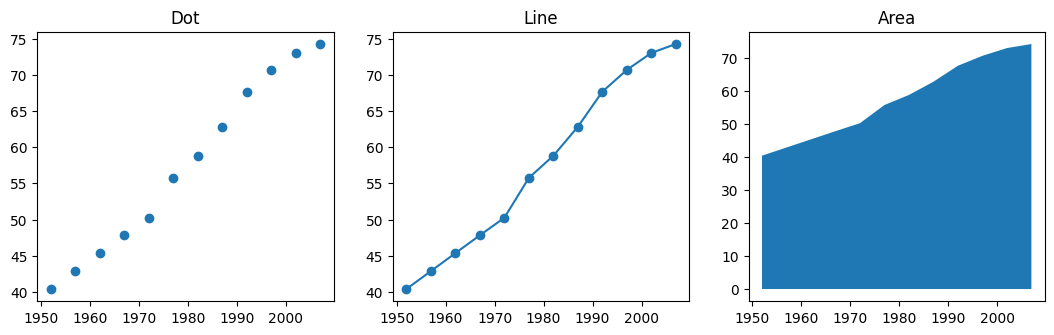

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
axs[0].plot(vn["year"], vn["lifeExp"], "o"); axs[0].set_title("Dot")
axs[1].plot(vn["year"], vn["lifeExp"], "-o"); axs[1].set_title("Line")
axs[2].fill_between(vn["year"], vn["lifeExp"]); axs[2].set_title("Area")
plt.show()

## Câu 3. Bar chart và biến thể

### 3a) Bar chart

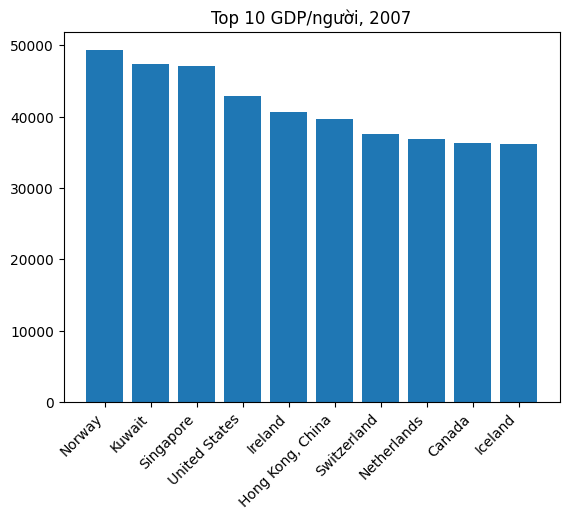

In [17]:
t10 = d07.nlargest(10, "gdpPercap")
plt.bar(t10["country"], t10["gdpPercap"])
plt.xticks(rotation=45, ha="right"); plt.title("Top 10 GDP/người, 2007"); plt.show()

### 3b) Bar chart ngang

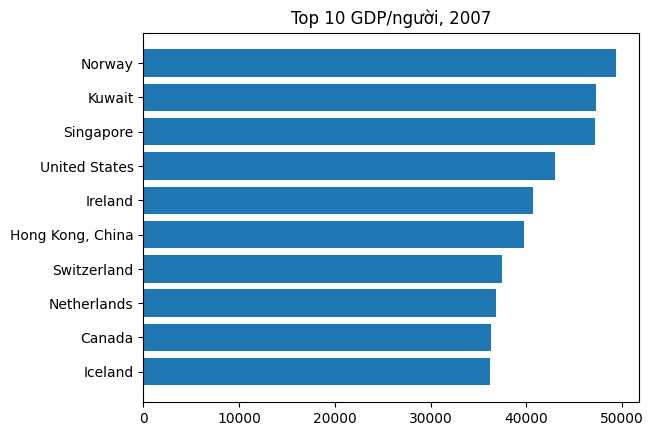

In [18]:
plt.barh(t10["country"][::-1], t10["gdpPercap"][::-1])
plt.title("Top 10 GDP/người, 2007"); plt.show()

### 3c) Grouped bar

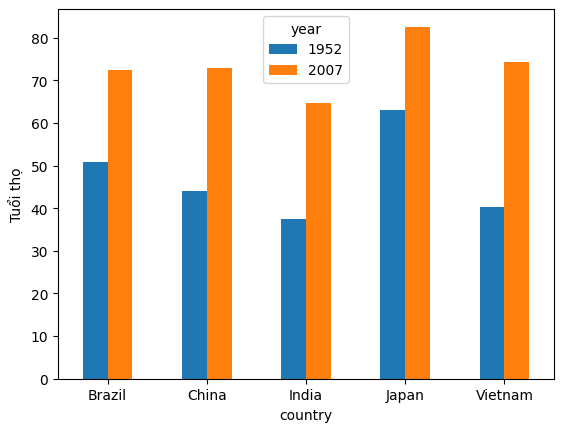

country
Vietnam    33.8
China      29.0
India      27.3
Brazil     21.5
Japan      19.6
dtype: float64


In [19]:
g = df[df["year"].isin([1952, 2007]) & df["country"].isin(five)].pivot(index="country", columns="year", values="lifeExp")
g.plot.bar(rot=0); plt.ylabel("Tuổi thọ"); plt.show()
print((g[2007] - g[1952]).sort_values(ascending=False).round(1))

### 3d) Stacked bar

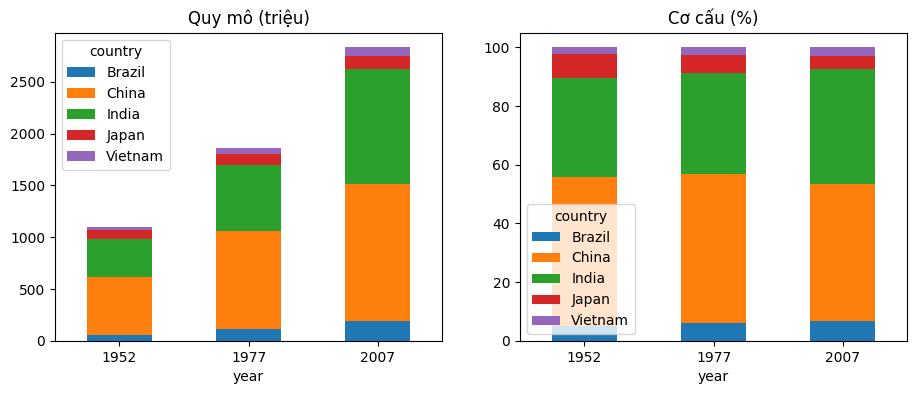

In [20]:
p = df[df["year"].isin([1952, 1977, 2007]) & df["country"].isin(five)].pivot(index="year", columns="country", values="pop") / 1e6
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
p.plot.bar(stacked=True, ax=axs[0], rot=0); axs[0].set_title("Quy mô (triệu)")
(p.div(p.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, ax=axs[1], rot=0); axs[1].set_title("Cơ cấu (%)")
plt.show()

### 3e) Grouped bar > 2 biến

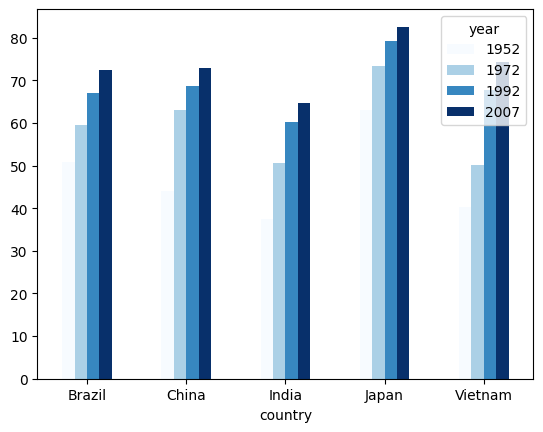

In [21]:
g4 = df[df["year"].isin([1952, 1972, 1992, 2007]) & df["country"].isin(five)].pivot(index="country", columns="year", values="lifeExp")
g4.plot.bar(rot=0, colormap="Blues"); plt.show()

### 3f) Radial column chart

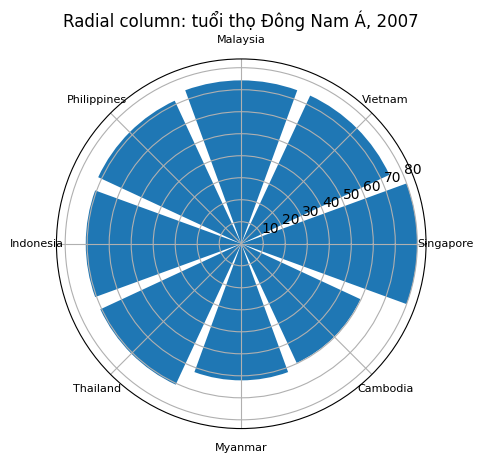

In [22]:
d = d07[d07["country"].isin(sea)].sort_values("lifeExp", ascending=False)
th = np.linspace(0, 2*np.pi, len(d), endpoint=False)
ax = plt.subplot(polar=True)
ax.bar(th, d["lifeExp"], width=0.7)
ax.set_xticks(th); ax.set_xticklabels(d["country"], fontsize=8)
plt.title("Radial column: tuổi thọ Đông Nam Á, 2007"); plt.show()

### 3g) Spiral plot

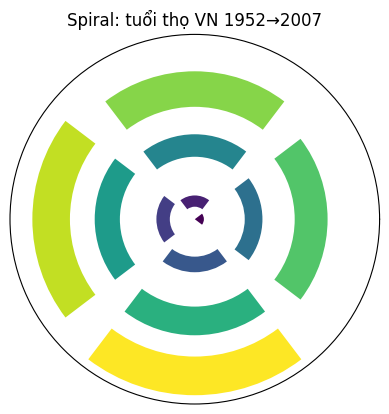

In [23]:
n = len(vn)
theta = 2*np.pi*np.arange(n)/4              # 4 điểm / vòng
r = 3 + np.arange(n)/4*2.6
ax = plt.subplot(polar=True)
ax.bar(theta, (vn["lifeExp"].values - 30)/22, width=1.3, bottom=r, color=plt.cm.viridis(np.linspace(0, 1, n)))
ax.set_xticks([]); ax.set_yticks([]); plt.title("Spiral: tuổi thọ VN 1952→2007"); plt.show()

### 3h) Trục bị cắt: bar vs dot

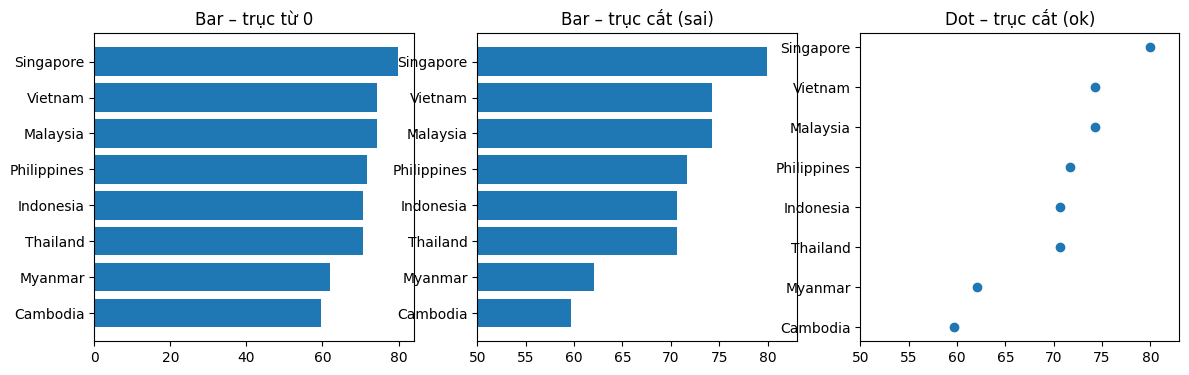

In [24]:
dd = d07[d07["country"].isin(sea)].sort_values("lifeExp")
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
axs[0].barh(dd["country"], dd["lifeExp"]); axs[0].set_title("Bar – trục từ 0")
axs[1].barh(dd["country"], dd["lifeExp"]); axs[1].set_xlim(50, 83); axs[1].set_title("Bar – trục cắt (sai)")
axs[2].plot(dd["lifeExp"], dd["country"], "o"); axs[2].set_xlim(50, 83); axs[2].set_title("Dot – trục cắt (ok)")
plt.show()

## Câu 4. Scatter và bubble chart

### 4a) Scatter plot

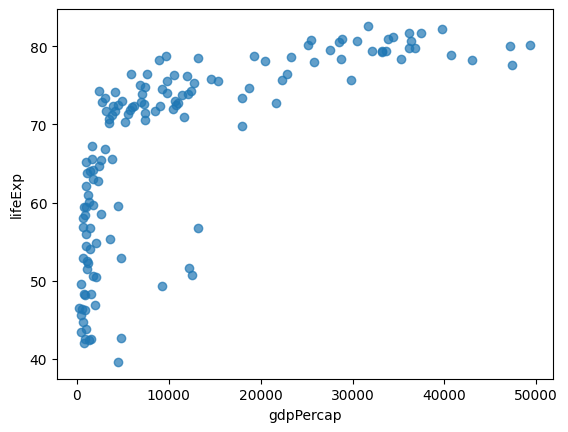

In [25]:
plt.scatter(d07["gdpPercap"], d07["lifeExp"], alpha=.7)
plt.xlabel("gdpPercap"); plt.ylabel("lifeExp"); plt.show()

### 4b) Thang log

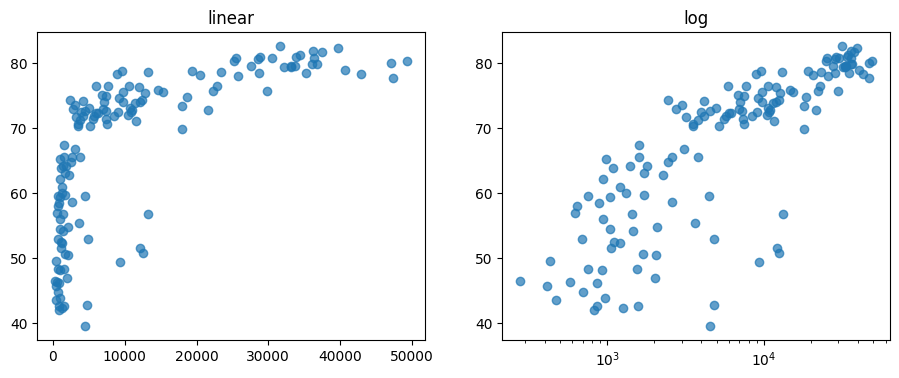

Pearson thô : 0.679
Pearson log : 0.809
Spearman    : 0.857


In [26]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, sc in zip(axs, ["linear", "log"]):
    ax.scatter(d07["gdpPercap"], d07["lifeExp"], alpha=.7)
    ax.set_xscale(sc); ax.set_title(sc)
plt.show()
x, y = d07["gdpPercap"], d07["lifeExp"]
print("Pearson thô :", round(np.corrcoef(x, y)[0, 1], 3))
print("Pearson log :", round(np.corrcoef(np.log10(x), y)[0, 1], 3))
print("Spearman    :", round(stats.spearmanr(x, y)[0], 3))

### 4c) Bubble chart

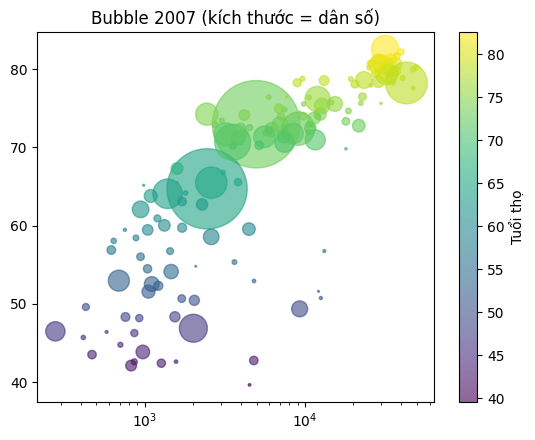

In [27]:
plt.scatter(d07["gdpPercap"], d07["lifeExp"], s=d07["pop"]/1e6*3, c=d07["lifeExp"], cmap="viridis", alpha=.6)
plt.xscale("log"); plt.colorbar(label="Tuổi thọ"); plt.title("Bubble 2007 (kích thước = dân số)"); plt.show()

### 4d) Thang căn bậc hai

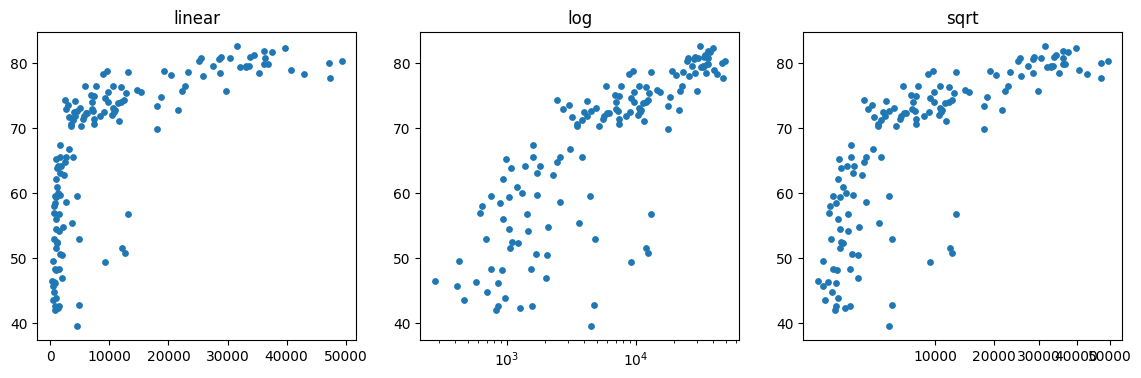

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, sc in zip(axs, ["linear", "log", "sqrt"]):
    ax.scatter(d07["gdpPercap"], d07["lifeExp"], s=15)
    if sc == "sqrt": ax.set_xscale("function", functions=(np.sqrt, np.square))
    else: ax.set_xscale(sc)
    ax.set_title(sc)
plt.show()

### 4e) Scatter có phân nhóm

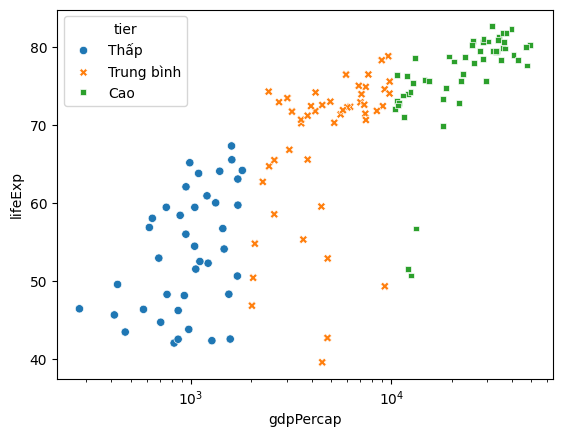

In [29]:
sns.scatterplot(data=d07, x="gdpPercap", y="lifeExp", hue="tier", style="tier")
plt.xscale("log"); plt.show()

### 4f) Bubble chart nhiều biến

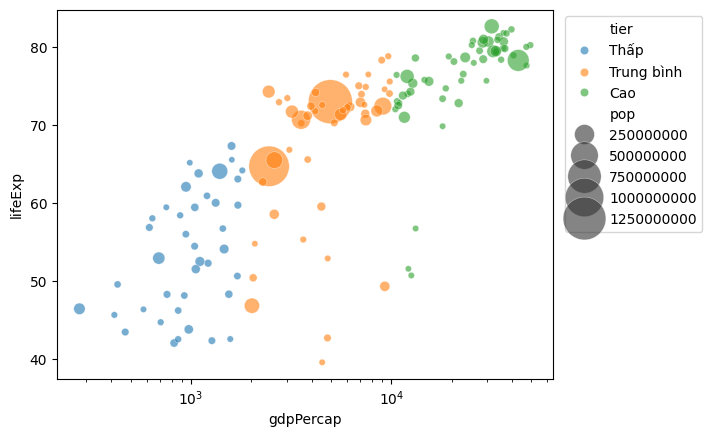

In [30]:
sns.scatterplot(data=d07, x="gdpPercap", y="lifeExp", size="pop", hue="tier", sizes=(20, 1000), alpha=.6)
plt.xscale("log"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.show()

### 4g) Connected scatter

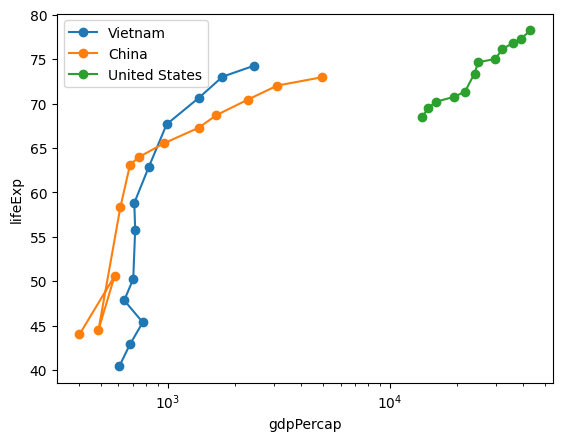

In [31]:
for c in ["Vietnam", "China", "United States"]:
    d = df[df["country"] == c]
    plt.plot(d["gdpPercap"], d["lifeExp"], "-o", label=c)
plt.xscale("log"); plt.legend(); plt.xlabel("gdpPercap"); plt.ylabel("lifeExp"); plt.show()

### 4h) Confidence band

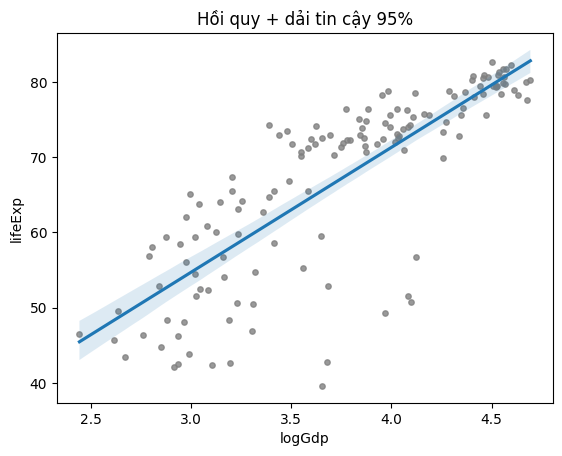

R² = 0.654


In [32]:
d07["logGdp"] = np.log10(d07["gdpPercap"])
sns.regplot(data=d07, x="logGdp", y="lifeExp", ci=95, scatter_kws={"s": 15, "color": "gray"})
plt.title("Hồi quy + dải tin cậy 95%"); plt.show()
r = np.corrcoef(d07["logGdp"], d07["lifeExp"])[0, 1]
print("R² =", round(r**2, 3))

### 4i) Confidence band + prediction band

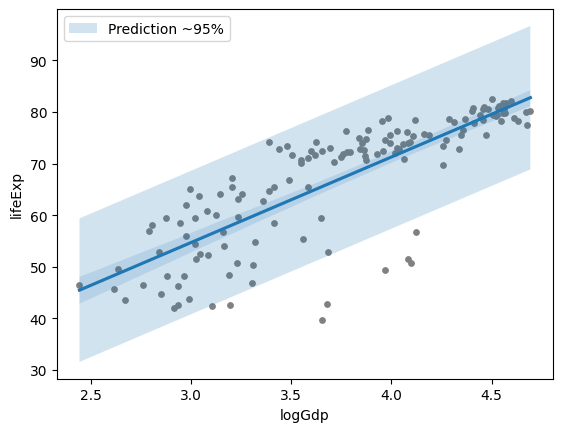

In [33]:
b1, b0 = np.polyfit(d07["logGdp"], d07["lifeExp"], 1)
xs = np.linspace(d07["logGdp"].min(), d07["logGdp"].max(), 100)
yhat = b0 + b1 * xs
s = (d07["lifeExp"] - (b0 + b1 * d07["logGdp"])).std()
plt.scatter(d07["logGdp"], d07["lifeExp"], s=15, color="gray")
plt.fill_between(xs, yhat - 1.96*s, yhat + 1.96*s, alpha=.2, label="Prediction ~95%")
sns.regplot(data=d07, x="logGdp", y="lifeExp", scatter=False, ci=95)
plt.legend(); plt.show()

## Câu 5. Phân phối dữ liệu

### 5a) Histogram

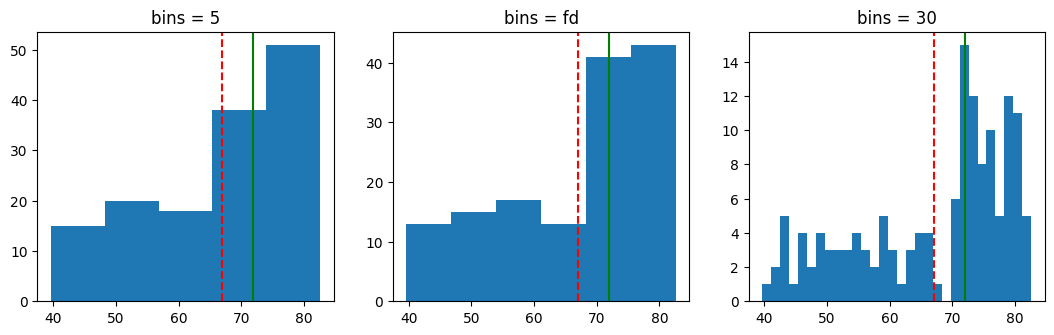

Skewness: -0.681


In [34]:
x = d07["lifeExp"]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, b in zip(axs, [5, "fd", 30]):
    ax.hist(x, bins=b)
    ax.axvline(x.mean(), color="r", ls="--"); ax.axvline(x.median(), color="g")
    ax.set_title(f"bins = {b}")
plt.show()
print("Skewness:", round(stats.skew(x), 3))

### 5b) Density plot

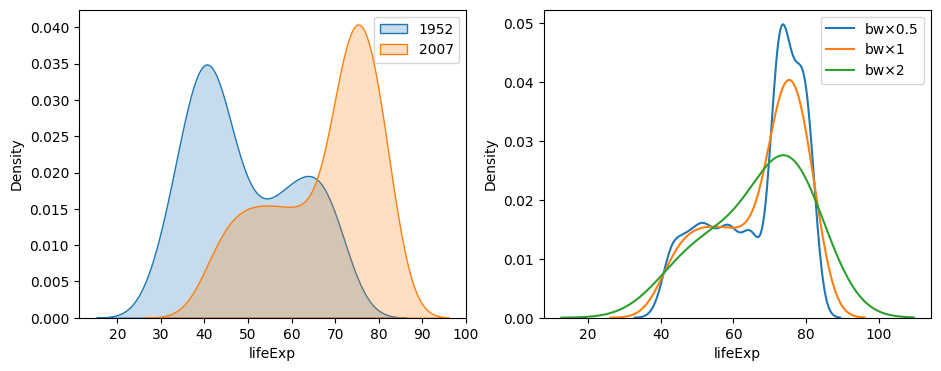

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for y in [1952, 2007]:
    sns.kdeplot(df[df["year"] == y]["lifeExp"], fill=True, label=y, ax=axs[0])
axs[0].legend()
for bw in [0.5, 1, 2]:
    sns.kdeplot(x, bw_adjust=bw, label=f"bw×{bw}", ax=axs[1])
axs[1].legend(); plt.show()

### 5c) Boxplot

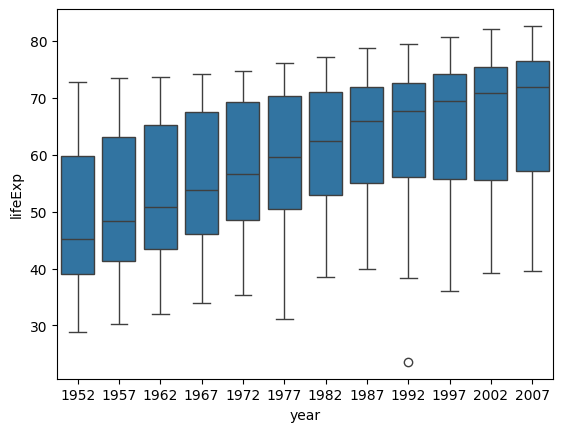

Q1, median, Q3, IQR: 57.16025 71.93549999999999 76.41325 19.253000000000007 | hàng rào: 28.280749999999987 105.29275000000001
Outlier: []


In [36]:
sns.boxplot(data=df, x="year", y="lifeExp"); plt.show()

q1, med, q3 = np.percentile(x, [25, 50, 75]); iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
print("Q1, median, Q3, IQR:", q1, med, q3, iqr, "| hàng rào:", lo, hi)
print("Outlier:", d07[(x < lo) | (x > hi)][["country", "lifeExp"]].values.tolist())

### 5d) Stacked density

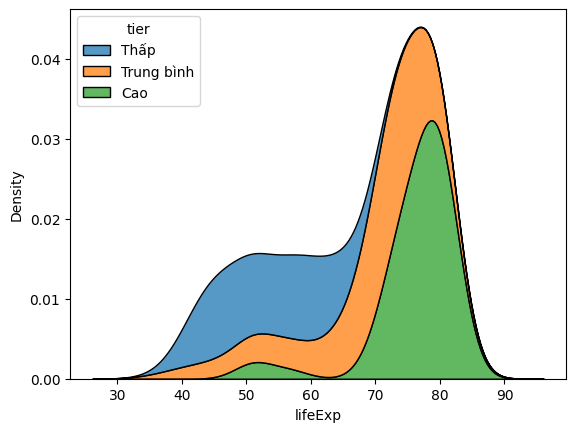

In [37]:
sns.kdeplot(data=d07, x="lifeExp", hue="tier", multiple="stack"); plt.show()

### 5e) Ridgeline

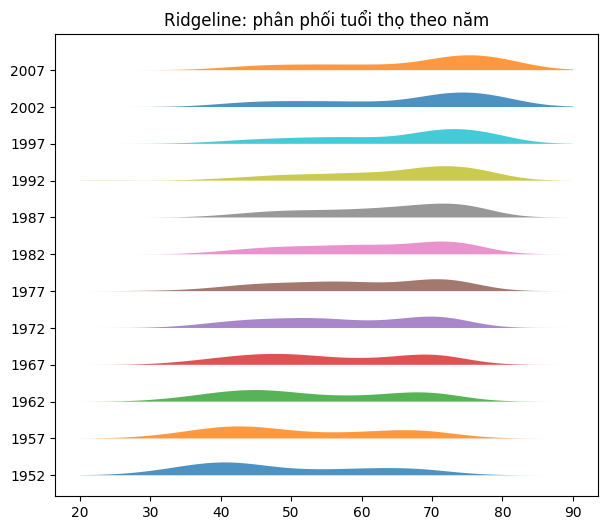

In [38]:
fig, ax = plt.subplots(figsize=(7, 6))
grid = np.linspace(20, 90, 300)
for i, y in enumerate(sorted(df["year"].unique())):
    dens = stats.gaussian_kde(df[df["year"] == y]["lifeExp"])(grid) * 10
    ax.fill_between(grid, i, i + dens, alpha=.8)
ax.set_yticks(range(12)); ax.set_yticklabels(sorted(df["year"].unique()))
ax.set_title("Ridgeline: phân phối tuổi thọ theo năm"); plt.show()

### 5f) Violin, strip, sina

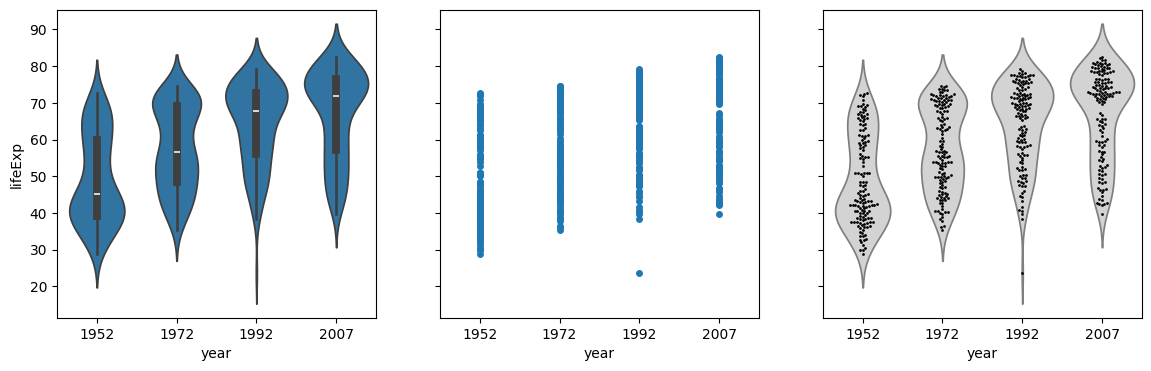

In [39]:
sel = df[df["year"].isin([1952, 1972, 1992, 2007])]
fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
sns.violinplot(data=sel, x="year", y="lifeExp", ax=axs[0])
sns.stripplot(data=sel, x="year", y="lifeExp", jitter=False, ax=axs[1])
sns.violinplot(data=sel, x="year", y="lifeExp", inner=None, color="lightgray", ax=axs[2])
sns.swarmplot(data=sel, x="year", y="lifeExp", size=2, color="k", ax=axs[2])
plt.show()

### 5g) Quantile dot plot

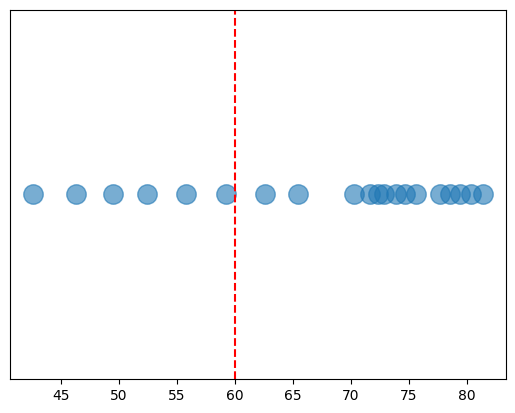

Số chấm < 60: 6 | thực tế: 30.3%


In [40]:
qd = np.quantile(x, (np.arange(20) + .5) / 20)      # 20 chấm, mỗi chấm = 5%
plt.plot(qd, np.zeros(20), "o", ms=14, alpha=.6)
plt.axvline(60, color="r", ls="--"); plt.yticks([]); plt.show()
print("Số chấm < 60:", (qd < 60).sum(), "| thực tế:", f"{(x < 60).mean():.1%}")

### 5h) Back-to-back histogram

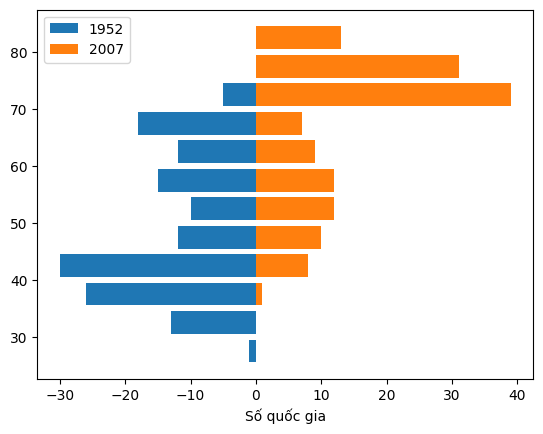

In [41]:
edges = np.arange(25, 90, 5)
c52, _ = np.histogram(df[df["year"] == 1952]["lifeExp"], edges)
c07, _ = np.histogram(x, edges)
plt.barh(edges[:-1] + 2.5, -c52, height=4, label="1952")
plt.barh(edges[:-1] + 2.5, c07, height=4, label="2007")
plt.legend(); plt.xlabel("Số quốc gia"); plt.show()

### 5i) Q-Q plot

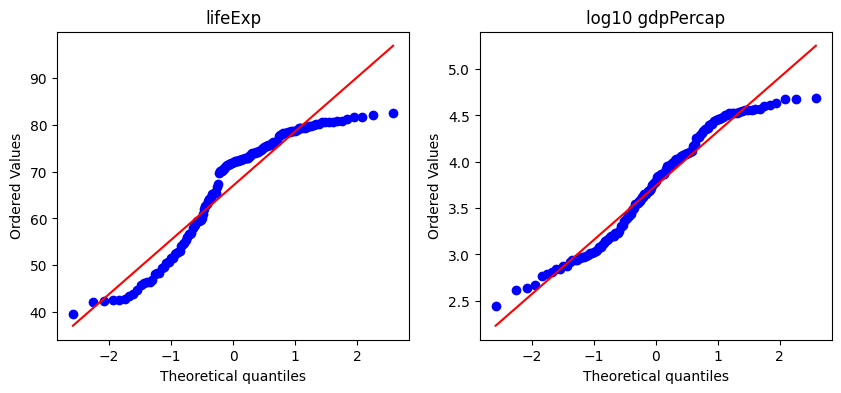

Shapiro p lifeExp: 1.357320139633981e-08


In [42]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(d07["lifeExp"], plot=axs[0]); axs[0].set_title("lifeExp")
stats.probplot(np.log10(d07["gdpPercap"]), plot=axs[1]); axs[1].set_title("log10 gdpPercap")
plt.show()
print("Shapiro p lifeExp:", stats.shapiro(d07["lifeExp"])[1])

### 5j) Error bar

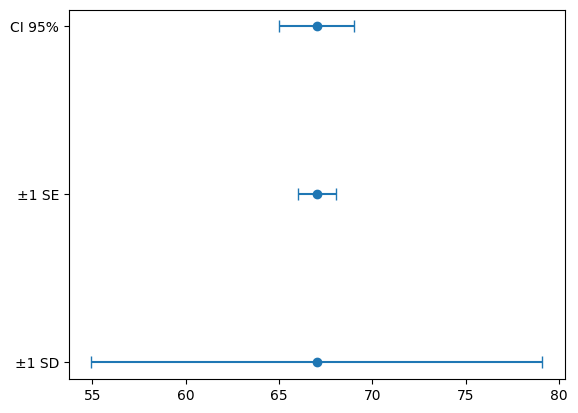

{'±1 SD': np.float64(12.07), '±1 SE': np.float64(1.01), 'CI 95%': np.float64(2.0)}


In [43]:
m, sd, n = x.mean(), x.std(), len(x); se = sd / np.sqrt(n)
t95 = stats.t.ppf(.975, n - 1)
labels = ["±1 SD", "±1 SE", "CI 95%"]; errs = [sd, se, t95 * se]
plt.errorbar([m]*3, range(3), xerr=errs, fmt="o", capsize=4)
plt.yticks(range(3), labels); plt.show()
print(dict(zip(labels, np.round(errs, 2))))

### 5k) Graded error bar

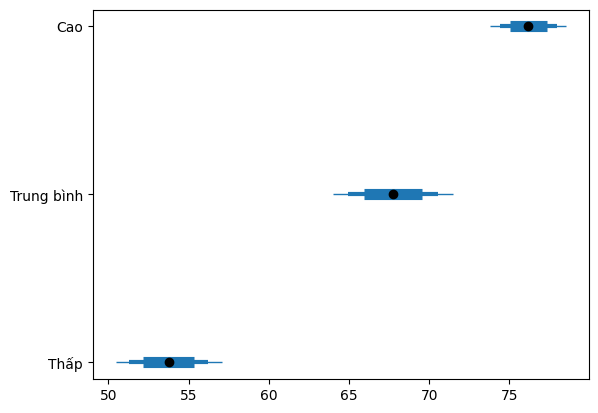

In [44]:
for i, t in enumerate(["Thấp", "Trung bình", "Cao"]):
    v = d07.loc[d07["tier"] == t, "lifeExp"]
    m, se = v.mean(), v.std() / np.sqrt(len(v))
    for lv, lw in [(.99, 1), (.95, 3), (.80, 8)]:
        h = stats.t.ppf((1 + lv) / 2, len(v) - 1) * se
        plt.hlines(i, m - h, m + h, lw=lw, color="C0")
    plt.plot(m, i, "ko")
plt.yticks(range(3), ["Thấp", "Trung bình", "Cao"]); plt.show()

### 5l) Span chart

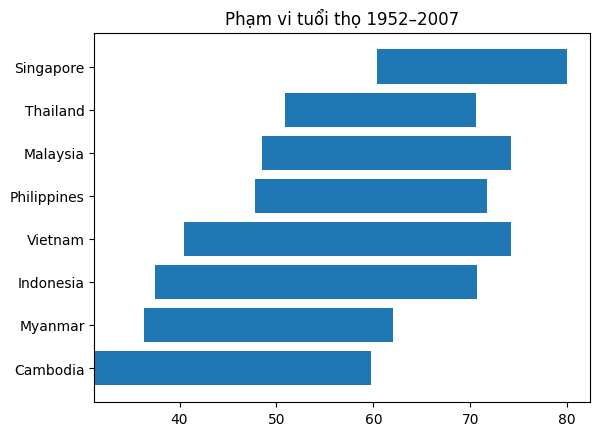

In [45]:
r = df[df["country"].isin(sea)].groupby("country")["lifeExp"].agg(["min", "max"]).sort_values("min")
plt.barh(r.index, r["max"] - r["min"], left=r["min"])
plt.title("Phạm vi tuổi thọ 1952–2007"); plt.show()

### 5m) So sánh bốn cách xem phân phối

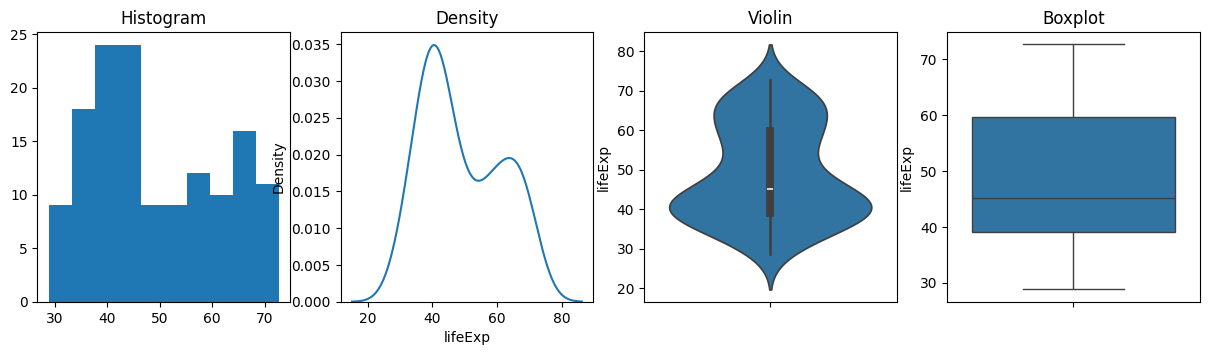

In [46]:
x52 = df[df["year"] == 1952]["lifeExp"]
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
axs[0].hist(x52); axs[0].set_title("Histogram")
sns.kdeplot(x52, ax=axs[1]); axs[1].set_title("Density")
sns.violinplot(y=x52, ax=axs[2]); axs[2].set_title("Violin")
sns.boxplot(y=x52, ax=axs[3]); axs[3].set_title("Boxplot")
plt.show()

## Câu 6. Heatmap, correlogram, pie và tỉ lệ nhiều biến

### 6a) Heatmap

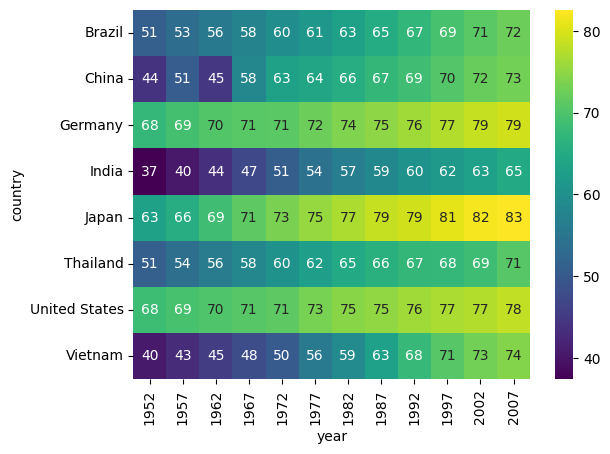

In [47]:
eight = ["Vietnam","Thailand","China","India","Japan","Brazil","Germany","United States"]
hm = df[df["country"].isin(eight)].pivot(index="country", columns="year", values="lifeExp")
sns.heatmap(hm, annot=True, fmt=".0f", cmap="viridis"); plt.show()

### 6b) Correlogram

           lifeExp    pop  gdpPercap
lifeExp      1.000  0.048      0.679
pop          0.048  1.000     -0.056
gdpPercap    0.679 -0.056      1.000


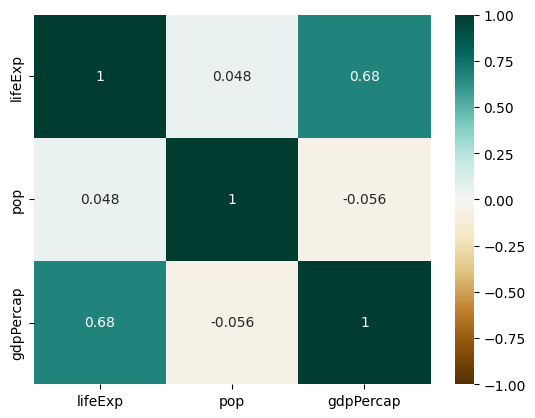

           lifeExp    pop  gdpPercap
lifeExp      1.000  0.003      0.857
pop          0.003  1.000     -0.065
gdpPercap    0.857 -0.065      1.000


In [48]:
cols = ["lifeExp", "pop", "gdpPercap"]
corr = d07[cols].corr()
print(corr.round(3))
sns.heatmap(corr, annot=True, cmap="BrBG", vmin=-1, vmax=1, center=0); plt.show()
print(d07[cols].corr("spearman").round(3))

### 6c) Pie và donut

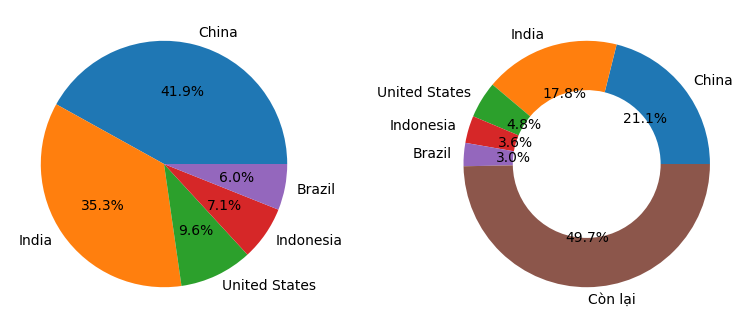

In [49]:
t5 = d07.nlargest(5, "pop")
rest = d07["pop"].sum() - t5["pop"].sum()
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].pie(t5["pop"], labels=t5["country"], autopct="%1.1f%%")
axs[1].pie(list(t5["pop"]) + [rest], labels=list(t5["country"]) + ["Còn lại"], autopct="%1.1f%%", wedgeprops=dict(width=.4))
plt.show()

### 6d) Heatmap thay đổi

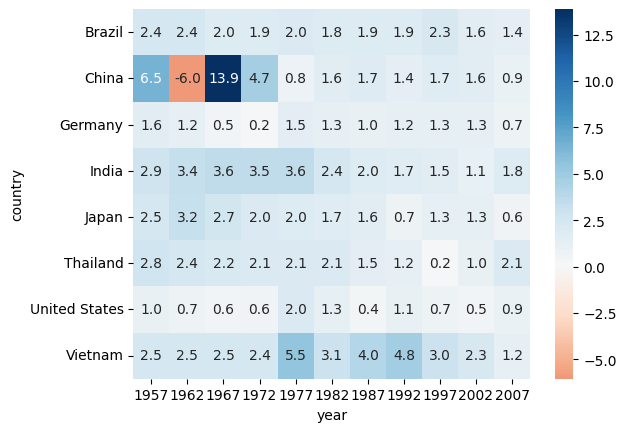

Số ô âm: 1


In [50]:
chg = hm.diff(axis=1).iloc[:, 1:]
sns.heatmap(chg, annot=True, fmt=".1f", cmap="RdBu", center=0); plt.show()
print("Số ô âm:", int((chg < 0).sum().sum()))

### 6e) Scatterplot matrix

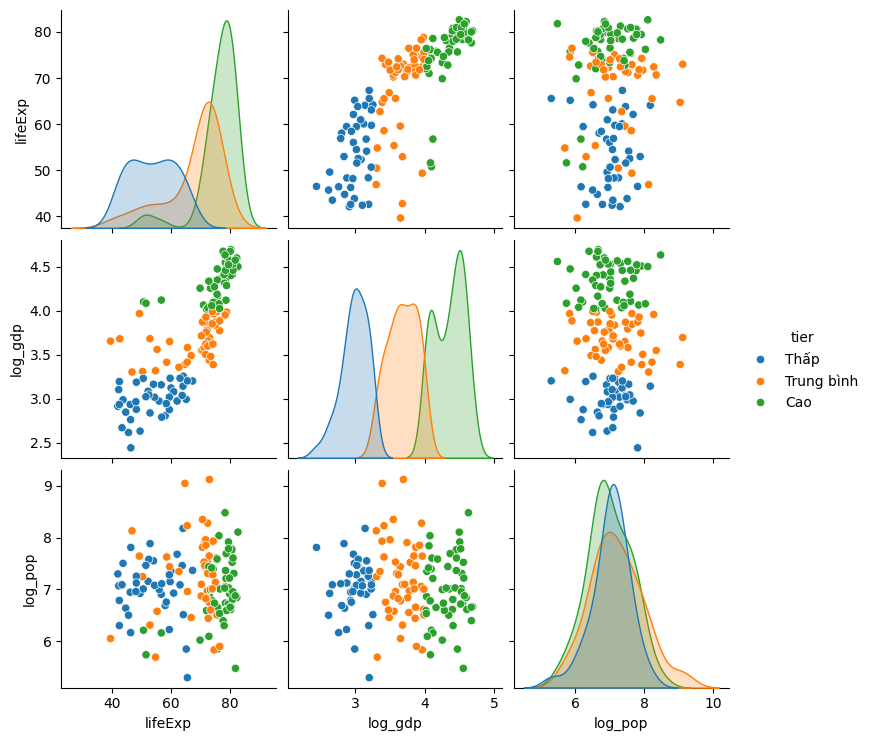

In [51]:
tmp = d07.assign(log_gdp=np.log10(d07["gdpPercap"]), log_pop=np.log10(d07["pop"]))
sns.pairplot(tmp, vars=["lifeExp", "log_gdp", "log_pop"], hue="tier"); plt.show()

### 6f) Parallel coordinates

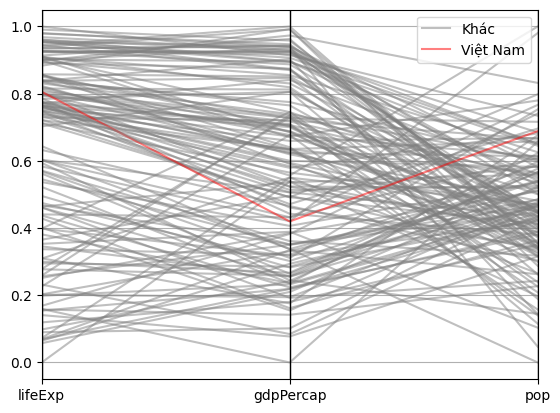

In [52]:
Z = d07[["country", "lifeExp", "gdpPercap", "pop"]].copy()
Z["gdpPercap"], Z["pop"] = np.log10(Z["gdpPercap"]), np.log10(Z["pop"])
for c in ["lifeExp", "gdpPercap", "pop"]:
    Z[c] = (Z[c] - Z[c].min()) / (Z[c].max() - Z[c].min())
Z["nhóm"] = np.where(Z["country"] == "Vietnam", "Việt Nam", "Khác")
pd.plotting.parallel_coordinates(Z.drop(columns="country"), "nhóm", color=["gray", "red"], alpha=.5)
plt.show()

### 6g) Slopegraph

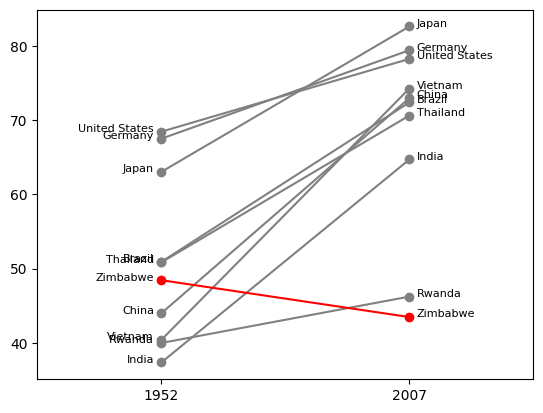

In [53]:
ten = eight + ["Zimbabwe", "Rwanda"]
sl = df[df["year"].isin([1952, 2007]) & df["country"].isin(ten)].pivot(index="country", columns="year", values="lifeExp")
for c, r in sl.iterrows():
    plt.plot([0, 1], [r[1952], r[2007]], "-o", color="red" if r[2007] < r[1952] else "gray")
    plt.text(-.03, r[1952], c, ha="right", fontsize=8)
    plt.text(1.03, r[2007], c, ha="left", fontsize=8)
plt.xticks([0, 1], ["1952", "2007"]); plt.xlim(-.5, 1.5); plt.show()

### 6h) Nested pies

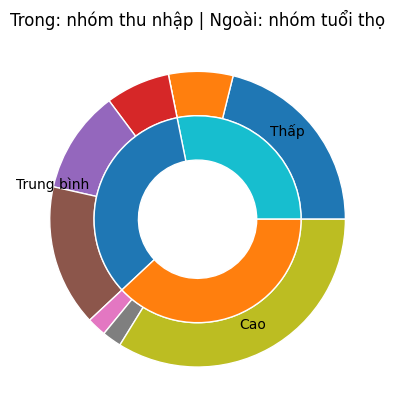

In [54]:
ct = pd.crosstab(d07["tier"], d07["lifeGrp"])
plt.pie(ct.values.flatten(), radius=1, wedgeprops=dict(width=.3, edgecolor="w"))
plt.pie(ct.sum(axis=1), labels=ct.index, radius=.7, wedgeprops=dict(width=.3, edgecolor="w"))
plt.title("Trong: nhóm thu nhập | Ngoài: nhóm tuổi thọ"); plt.show()

### 6i) Marimekko

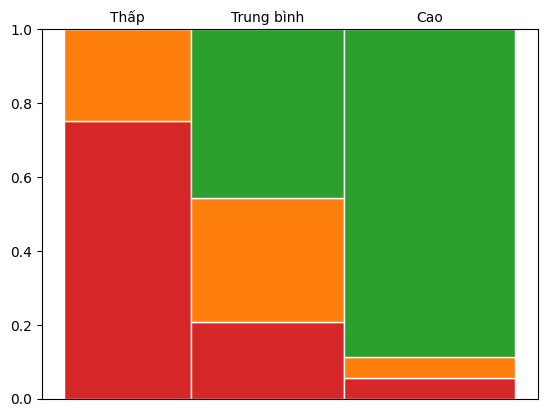

In [55]:
w = ct.sum(axis=1) / ct.values.sum()          # độ rộng cột = tỉ trọng nhóm
x0 = 0
for t in ct.index:
    bottom = 0
    for g in ct.columns:
        h = ct.loc[t, g] / ct.loc[t].sum()
        plt.bar(x0, h, width=w[t], bottom=bottom, align="edge", edgecolor="w", color={"<60": "C3", "60–72": "C1", ">72": "C2"}[g])
        bottom += h
    plt.text(x0 + w[t]/2, 1.02, t, ha="center"); x0 += w[t]
plt.xticks([]); plt.show()

### 6j) Treemap

In [56]:
import squarify
agg = d07.groupby(["tier", "lifeGrp"], observed=True)["pop"].sum() / 1e6
squarify.plot(sizes=agg.values, label=[f"{a}\n{b}\n{v:,.0f} tr" for (a, b), v in agg.items()], pad=True)
plt.axis("off"); plt.show()

ModuleNotFoundError: No module named 'squarify'

### 6k) Parallel sets

In [ ]:
import plotly.express as px
ps = d07.assign(pop_grp=pd.cut(d07["pop"], [0, 1e7, 1e8, np.inf], labels=["<10tr", "10–100tr", ">100tr"]))
px.parallel_categories(ps, dimensions=["tier", "lifeGrp", "pop_grp"]).show()

### 6l) Pie vs donut vs bar vs stacked bar

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
axs[0].pie(t5["pop"], labels=t5["country"]); axs[0].set_title("Pie")
axs[1].pie(t5["pop"], labels=t5["country"], wedgeprops=dict(width=.4)); axs[1].set_title("Donut")
axs[2].bar(t5["country"], t5["pop"] / 1e6); axs[2].set_title("Bar"); axs[2].tick_params(axis="x", rotation=30)
bt = 0
for c, v in zip(t5["country"], t5["pop"] / t5["pop"].sum()):
    axs[3].bar(0, v, bottom=bt, label=c); bt += v
axs[3].legend(fontsize=7); axs[3].set_title("Stacked 100%")
plt.show()

## Câu 7. Biểu đồ mở rộng

### 7a) Word cloud

In [ ]:
from wordcloud import WordCloud
freq = dict(zip(d07["country"], d07["pop"]))
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, f in zip(axs, [freq, {k: np.sqrt(v) for k, v in freq.items()}]):
    ax.imshow(WordCloud(background_color="white").generate_from_frequencies(f)); ax.axis("off")
axs[0].set_title("Trọng số thô"); axs[1].set_title("Trọng số căn bậc hai")
plt.show()

### 7b) Frequency framing (waffle)

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(11, 4))
for ax, y in zip(axs, [1952, 1977, 2007]):
    p = (df[df["year"] == y]["lifeExp"] >= 70).mean()
    k = int(round(p * 100))
    cells = np.array([1]*k + [0]*(100 - k)).reshape(10, 10)
    ax.imshow(cells, cmap="Blues"); ax.axis("off"); ax.set_title(f"{y}: {p:.0%}")
plt.show()

### 7c) Candlestick và OHLC

In [ ]:
med = df.groupby("year")["lifeExp"].median()
o = pd.DataFrame({"open": med.shift(1), "close": med,
                  "high": df.groupby("year")["lifeExp"].max(),
                  "low": df.groupby("year")["lifeExp"].min()}).dropna()
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for i, (y, r) in enumerate(o.iterrows()):
    col = "green" if r["close"] >= r["open"] else "red"
    axs[0].vlines(i, r["low"], r["high"], color="k")
    axs[0].bar(i, abs(r["close"] - r["open"]), bottom=min(r["open"], r["close"]), color=col)          # candlestick
    axs[1].vlines(i, r["low"], r["high"], color=col)
    axs[1].hlines(r["open"], i - .3, i, color=col); axs[1].hlines(r["close"], i, i + .3, color=col)  # OHLC
for ax in axs: ax.set_xticks(range(len(o))); ax.set_xticklabels(o.index, fontsize=7)
axs[0].set_title("Candlestick"); axs[1].set_title("OHLC")
plt.show()

### 7d) Choropleth và bubble map

In [ ]:
import plotly.express as px
px.choropleth(d07, locations="country", locationmode="country names", color="lifeExp",
              color_continuous_scale="Viridis", title="Tuổi thọ 2007").show()
px.scatter_geo(d07, locations="country", locationmode="country names", size="pop", color="tier",
               title="Bubble map 2007").show()

## Câu 8. Sơ đồ gắn với dữ liệu

### 8a) Tree diagram (dendrogram)

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
sel16 = sea + ["China", "India", "Japan", "Brazil", "Germany", "United States", "Rwanda", "Zimbabwe"]
F = d07.set_index("country").loc[sel16, ["lifeExp", "gdpPercap", "pop"]].copy()
F["gdpPercap"], F["pop"] = np.log10(F["gdpPercap"]), np.log10(F["pop"])
Zs = stats.zscore(F.values, axis=0)
Lk = linkage(Zs, "ward")
dendrogram(Lk, labels=F.index.tolist(), orientation="right"); plt.show()
cl = pd.Series(fcluster(Lk, 3, "maxclust"), index=F.index)
for k, g in cl.groupby(cl): print("Cụm", k, ":", ", ".join(g.index))

### 8b) Network diagram

In [ ]:
import networkx as nx
from scipy.spatial.distance import cdist
D = cdist(Zs, Zs); np.fill_diagonal(D, np.inf)
names = list(F.index)
G = nx.Graph()
for i, nm in enumerate(names):
    for j in np.argsort(D[i])[:2]:          # nối 2 nước gần nhất
        G.add_edge(nm, names[j])
nx.draw_networkx(G, nx.spring_layout(G, seed=3), node_color="lightblue", font_size=7)
plt.axis("off"); plt.show()

### 8c) Venn diagram

In [ ]:
from matplotlib_venn import venn3
A = set(d07.loc[d07["lifeExp"] >= 75, "country"])
B = set(d07.loc[d07["gdpPercap"] >= 20000, "country"])
C = set(d07.loc[d07["pop"] >= 50e6, "country"])
venn3([A, B, C], ("Tuổi thọ ≥ 75", "GDP/người ≥ 20k", "Dân số ≥ 50tr")); plt.show()
print("A∩B∩C:", sorted(A & B & C))

### 8d) Flowchart

In [ ]:
steps = ["Bắt đầu", "Đọc dữ liệu", "Kiểm tra (NaN, trùng)", "Làm sạch / biến đổi", "Chọn biểu đồ", "Vẽ biểu đồ", "Nhận xét", "Kết thúc"]
fig, ax = plt.subplots(figsize=(4, 8)); ax.axis("off"); ax.set_ylim(-1, len(steps))
for i, s in enumerate(steps):
    y = len(steps) - 1 - i
    ax.text(0.5, y, s, ha="center", va="center", bbox=dict(boxstyle="round", fc="lightblue"))
    if i < len(steps) - 1: ax.annotate("", (0.5, y - .75), (0.5, y - .25), arrowprops=dict(arrowstyle="->"))
plt.show()

### 8e) Mindmap

In [ ]:
branches = {"country": ["dot plot", "bar", "heatmap"], "year": ["line", "area", "slopegraph"],
            "lifeExp": ["histogram", "violin", "boxplot"], "pop": ["log", "bubble size", "treemap"],
            "gdpPercap": ["scatter log", "choropleth", "q-q"]}
G = nx.Graph()
for b, leaves in branches.items():
    G.add_edge("Gapminder", b)
    for l in leaves: G.add_edge(b, l)
nx.draw_networkx(G, nx.spring_layout(G, seed=1), node_color="lightyellow", font_size=8)
plt.axis("off"); plt.show()

### 8f) Gantt chart

In [ ]:
tasks = [("Khám phá dữ liệu", 0, 2, 0, 2), ("Làm sạch", 2, 1, 2, 2), ("Biểu đồ xu thế", 3, 3, 4, 3),
         ("Biểu đồ phân phối", 6, 3, 7, 4), ("Viết báo cáo", 9, 2, 11, 3)]   # (tên, KH bắt đầu, KH dài, TT bắt đầu, TT dài)
for i, (n, ps, pd_, as_, ad) in enumerate(tasks):
    plt.barh(i, pd_, left=ps, color="lightgray", hatch="//")
    plt.barh(i, ad, left=as_, height=.3, color="C0")
plt.yticks(range(len(tasks)), [t[0] for t in tasks]); plt.gca().invert_yaxis()
plt.xlabel("Ngày"); plt.title("Kế hoạch (xám) vs thực tế (xanh)"); plt.show()

### 8g) Fishbone diagram

In [ ]:
low = d07[d07["lifeExp"] < 55]
rest_ = d07[d07["lifeExp"] >= 55]
print("Số nước tuổi thọ < 55:", len(low))
print("GDP/người trung vị:", low["gdpPercap"].median().round(0), "vs", rest_["gdpPercap"].median().round(0))
causes = {"Kinh tế": "gdpPercap thấp", "Y tế": "thiếu cơ sở, vắc-xin", "Dịch bệnh": "HIV/AIDS, sốt rét",
          "Thể chế": "xung đột, quản trị yếu"}
fig, ax = plt.subplots(figsize=(10, 4)); ax.axis("off")
ax.annotate("", (9, 0), (0, 0), arrowprops=dict(arrowstyle="-|>", lw=2))
ax.text(9.2, 0, "Tuổi thọ < 55", va="center", fontweight="bold")
for i, (k, v) in enumerate(causes.items()):
    x = 1.5 + i * 2; y = 2 if i % 2 == 0 else -2
    ax.plot([x - .8, x], [y, 0], color="gray")
    ax.text(x - .8, y * 1.15, f"{k}\n{v}", ha="center", fontsize=8)
ax.set_ylim(-3.5, 3.5); plt.show()

## Câu 9. Tổng hợp, phản biện và gỡ lỗi

### 9a) Gỡ lỗi (bản đã sửa)

In [ ]:
df = pd.read_excel("gap-every-five-years.xlsx")
df["gdp"] = df["gdpPercap"] * df["pop"]             # (1) df["pop"], không phải df.pop
d = df[df["year"] == 2007]                          # (2) year là số nguyên, không phải "2007"
top = d.nlargest(10, "gdpPercap")                   # (3) nlargest cho 10 nước CAO nhất

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].barh(top["country"][::-1], top["gdpPercap"][::-1])   # (4) bar luôn bắt đầu từ 0
t5 = d.nlargest(5, "pop")
axs[1].pie(list(t5["pop"]) + [d["pop"].sum() - t5["pop"].sum()],
           labels=list(t5["country"]) + ["Còn lại"])         # (5) không pie 142 lát
sns.heatmap(df[["lifeExp", "pop", "gdpPercap"]].corr(), annot=True, cmap="BrBG", vmin=-1, vmax=1, ax=axs[2])  # (6) chỉ cột số
plt.show()

### 9b) Biểu đồ xấu – tốt

In [ ]:
dd = d07[d07["country"].isin(sea)].sort_values("lifeExp")
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].bar(dd["country"], dd["lifeExp"]); axs[0].set_ylim(60, 83); axs[0].set_title("XẤU: trục cắt tại 60")
axs[1].bar(dd["country"], dd["lifeExp"]); axs[1].set_ylim(0, 85); axs[1].set_title("TỐT: trục từ 0")
for a in axs: a.tick_params(axis="x", rotation=60)
plt.show()

### 9c, 9d) Câu lý thuyết
Không có mã.